# Tutorial: Recurrent Neural Networks in PyTorch

 This notebook is a practical tutorial to understand and build RNNs in PyTorch for:
 - Many-to-One tasks (sequence classification)
 - Many-to-Many tasks (sequence labeling)

## Learning goals:
 1. Build RNN architectures with nn.RNN.
 2. Train and evaluate with relevant metrics.
 3. Compare many-to-one vs many-to-many formulations.
 4. Complete guided exercises.

print('Notebook initialized. Start running the cells in order.')

## 0) Setup
We will use:
- `torch` for modeling and optimization
- `matplotlib` for simple visualization
- `sklearn.metrics` for evaluation metrics

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cpu


## 1) Synthetic Data
We will create two datasets:

1. **Many-to-One**: one label per sequence.
- Example: classify whether the average trend is positive.

2. **Many-to-Many**: one label per time step.
- Example: detect if each step is above a threshold (token-wise labeling).

In [2]:
def make_many_to_one_data(n_samples=1500, seq_len=20, input_size=1):
    X = torch.randn(n_samples, seq_len, input_size)
    # Label = 1 if mean of full sequence > 0, else 0.
    y = (X.mean(dim=1) > 0).float()
    return X, y


def make_many_to_many_data(n_samples=1500, seq_len=20, input_size=1):
    X = torch.randn(n_samples, seq_len, input_size)
    # Label at each time step: 1 if x_t > 0 else 0.
    y = (X > 0).float()
    return X, y


X_m21, y_m21 = make_many_to_one_data()
X_m2m, y_m2m = make_many_to_many_data()

print('Many-to-One shapes:', X_m21.shape, y_m21.shape)
print('Many-to-Many shapes:', X_m2m.shape, y_m2m.shape)

Many-to-One shapes: torch.Size([1500, 20, 1]) torch.Size([1500, 1])
Many-to-Many shapes: torch.Size([1500, 20, 1]) torch.Size([1500, 20, 1])


In [3]:
def train_val_split(X, y, val_ratio=0.2):
    n = X.size(0)
    idx = torch.randperm(n)
    split = int(n * (1 - val_ratio))
    tr_idx, va_idx = idx[:split], idx[split:]
    return X[tr_idx], y[tr_idx], X[va_idx], y[va_idx]


def make_loader(X, y, batch_size=64, shuffle=True):
    ds = TensorDataset(X, y)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


Xtr_21, ytr_21, Xva_21, yva_21 = train_val_split(X_m21, y_m21)
Xtr_m2m, ytr_m2m, Xva_m2m, yva_m2m = train_val_split(X_m2m, y_m2m)

train_loader_21 = make_loader(Xtr_21, ytr_21)
val_loader_21 = make_loader(Xva_21, yva_21, shuffle=False)
train_loader_m2m = make_loader(Xtr_m2m, ytr_m2m)
val_loader_m2m = make_loader(Xva_m2m, yva_m2m, shuffle=False)

print('Data loaders ready.')

Data loaders ready.


## 2) Model Construction
### A) Many-to-One RNN
- Input: `(batch, seq, input_size)`
- RNN returns hidden states for all time steps.
- We use the final hidden state for classification.

### B) Many-to-Many RNN
- Input: `(batch, seq, input_size)`
- We classify each time step using all RNN outputs.

In [4]:
class ManyToOneRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        last = out[:, -1, :]
        logits = self.fc(last)
        return logits


class ManyToManyRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        logits = self.fc(out)
        return logits


m21_model = ManyToOneRNN().to(device)
m2m_model = ManyToManyRNN().to(device)
print(m21_model)
print(m2m_model)

ManyToOneRNN(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
ManyToManyRNN(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


## 3) Training and Metrics
We will report:
- Loss (`BCEWithLogitsLoss`)
- Accuracy
- Precision
- Recall
- F1-score

In [5]:
criterion = nn.BCEWithLogitsLoss()


def compute_binary_metrics(y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        'acc': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
    }


def train_epoch_many_to_one(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    probs_all, y_all = [], []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)
        probs = torch.sigmoid(logits).detach().cpu().numpy().ravel()
        true = yb.detach().cpu().numpy().ravel()
        probs_all.append(probs)
        y_all.append(true)

    probs_all = np.concatenate(probs_all)
    y_all = np.concatenate(y_all)
    metrics = compute_binary_metrics(y_all, probs_all)
    return total_loss / len(loader.dataset), metrics


def eval_many_to_one(model, loader):
    model.eval()
    total_loss = 0.0
    probs_all, y_all = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)

            probs = torch.sigmoid(logits).cpu().numpy().ravel()
            true = yb.cpu().numpy().ravel()
            probs_all.append(probs)
            y_all.append(true)

    probs_all = np.concatenate(probs_all)
    y_all = np.concatenate(y_all)
    metrics = compute_binary_metrics(y_all, probs_all)
    return total_loss / len(loader.dataset), metrics


def train_epoch_many_to_many(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    probs_all, y_all = [], []

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)
        probs = torch.sigmoid(logits).detach().cpu().numpy().reshape(-1)
        true = yb.detach().cpu().numpy().reshape(-1)
        probs_all.append(probs)
        y_all.append(true)

    probs_all = np.concatenate(probs_all)
    y_all = np.concatenate(y_all)
    metrics = compute_binary_metrics(y_all, probs_all)
    return total_loss / len(loader.dataset), metrics


def eval_many_to_many(model, loader):
    model.eval()
    total_loss = 0.0
    probs_all, y_all = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)

            probs = torch.sigmoid(logits).cpu().numpy().reshape(-1)
            true = yb.cpu().numpy().reshape(-1)
            probs_all.append(probs)
            y_all.append(true)

    probs_all = np.concatenate(probs_all)
    y_all = np.concatenate(y_all)
    metrics = compute_binary_metrics(y_all, probs_all)
    return total_loss / len(loader.dataset), metrics

In [6]:
def fit_many_to_one(model, train_loader, val_loader, epochs=12, lr=1e-2):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_metrics = train_epoch_many_to_one(model, train_loader, optimizer)
        va_loss, va_metrics = eval_many_to_one(model, val_loader)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_f1'].append(tr_metrics['f1'])
        history['val_f1'].append(va_metrics['f1'])

        print(
            f"[M21][Epoch {epoch:02d}] "
            f"train_loss={tr_loss:.4f}, val_loss={va_loss:.4f}, "
            f"train_f1={tr_metrics['f1']:.4f}, val_f1={va_metrics['f1']:.4f}"
        )

    return history


def fit_many_to_many(model, train_loader, val_loader, epochs=12, lr=1e-2):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_metrics = train_epoch_many_to_many(model, train_loader, optimizer)
        va_loss, va_metrics = eval_many_to_many(model, val_loader)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_f1'].append(tr_metrics['f1'])
        history['val_f1'].append(va_metrics['f1'])

        print(
            f"[M2M][Epoch {epoch:02d}] "
            f"train_loss={tr_loss:.4f}, val_loss={va_loss:.4f}, "
            f"train_f1={tr_metrics['f1']:.4f}, val_f1={va_metrics['f1']:.4f}"
        )

    return history


def plot_history(history, title):
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epoch')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['train_f1'], label='Train F1')
    plt.plot(history['val_f1'], label='Val F1')
    plt.title(f'{title} - F1')
    plt.xlabel('Epoch')
    plt.legend()

    plt.tight_layout()
    plt.show()

## 4) Example A: Many-to-One (Sequence Classification)
In this example, each sequence has one label.

Try changing:
- `hidden_size`
- `num_layers`
- learning rate
- sequence length in data generation

[M21][Epoch 01] train_loss=0.4820, val_loss=0.3078, train_f1=0.7754, val_f1=0.8602
[M21][Epoch 02] train_loss=0.3015, val_loss=0.2566, train_f1=0.8763, val_f1=0.8865
[M21][Epoch 03] train_loss=0.2469, val_loss=0.2989, train_f1=0.8998, val_f1=0.8684
[M21][Epoch 04] train_loss=0.2561, val_loss=0.2441, train_f1=0.8985, val_f1=0.8722
[M21][Epoch 05] train_loss=0.2971, val_loss=0.2937, train_f1=0.8726, val_f1=0.8818
[M21][Epoch 06] train_loss=0.2717, val_loss=0.2371, train_f1=0.8852, val_f1=0.8961
[M21][Epoch 07] train_loss=0.2247, val_loss=0.2302, train_f1=0.9221, val_f1=0.9059
[M21][Epoch 08] train_loss=0.2456, val_loss=0.2197, train_f1=0.8891, val_f1=0.9147
[M21][Epoch 09] train_loss=0.2431, val_loss=0.2446, train_f1=0.9050, val_f1=0.9024
[M21][Epoch 10] train_loss=0.1835, val_loss=0.1695, train_f1=0.9266, val_f1=0.9433
[M21][Epoch 11] train_loss=0.1884, val_loss=0.1812, train_f1=0.9275, val_f1=0.9338
[M21][Epoch 12] train_loss=0.2649, val_loss=0.2885, train_f1=0.8809, val_f1=0.8624


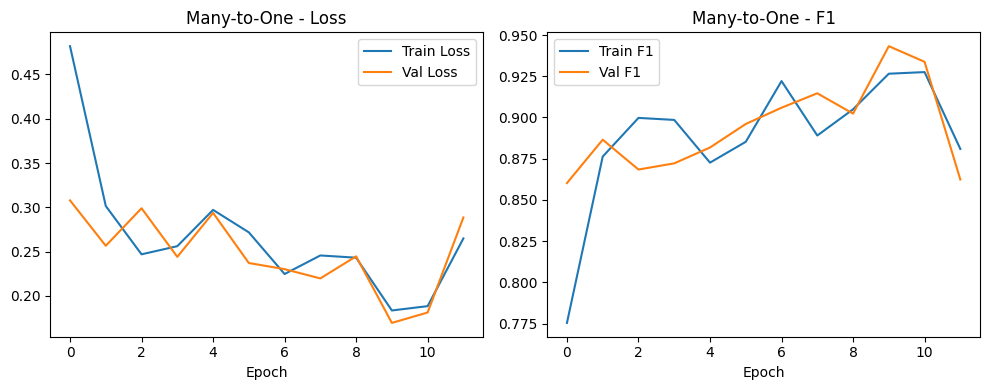

Final Many-to-One validation metrics: {'acc': 0.85, 'precision': 0.7663043478260869, 'recall': 0.986013986013986, 'f1': 0.8623853211009174}


In [7]:
m21_model = ManyToOneRNN(input_size=1, hidden_size=32, num_layers=1).to(device)
history_m21 = fit_many_to_one(
    m21_model,
    train_loader_21,
    val_loader_21,
    epochs=12,
    lr=1e-2,
)
plot_history(history_m21, 'Many-to-One')

val_loss_21, val_metrics_21 = eval_many_to_one(m21_model, val_loader_21)
print('Final Many-to-One validation metrics:', val_metrics_21)

## 5) Example B: Many-to-Many (Sequence Labeling)
Now each time step receives a label.

The output shape is `(batch, seq, 1)`, and loss is computed across all time steps.

[M2M][Epoch 01] train_loss=0.5048, val_loss=0.3187, train_f1=0.9113, val_f1=0.9812
[M2M][Epoch 02] train_loss=0.2225, val_loss=0.1510, train_f1=0.9826, val_f1=0.9748
[M2M][Epoch 03] train_loss=0.1193, val_loss=0.0963, train_f1=0.9869, val_f1=0.9945
[M2M][Epoch 04] train_loss=0.0848, val_loss=0.0756, train_f1=0.9906, val_f1=0.9965
[M2M][Epoch 05] train_loss=0.0681, val_loss=0.0642, train_f1=0.9936, val_f1=0.9940
[M2M][Epoch 06] train_loss=0.0583, val_loss=0.0629, train_f1=0.9939, val_f1=0.9817
[M2M][Epoch 07] train_loss=0.0534, val_loss=0.0530, train_f1=0.9890, val_f1=0.9875
[M2M][Epoch 08] train_loss=0.0463, val_loss=0.0450, train_f1=0.9929, val_f1=0.9968
[M2M][Epoch 09] train_loss=0.0408, val_loss=0.0430, train_f1=0.9965, val_f1=0.9910
[M2M][Epoch 10] train_loss=0.0388, val_loss=0.0450, train_f1=0.9926, val_f1=0.9846
[M2M][Epoch 11] train_loss=0.0368, val_loss=0.0423, train_f1=0.9920, val_f1=0.9844
[M2M][Epoch 12] train_loss=0.0339, val_loss=0.0332, train_f1=0.9945, val_f1=0.9965


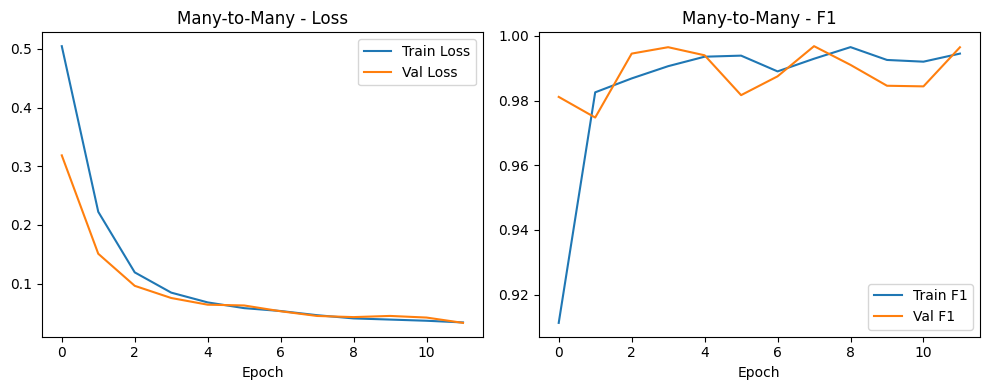

Final Many-to-Many validation metrics: {'acc': 0.9965, 'precision': 0.999330207635633, 'recall': 0.9936729936729937, 'f1': 0.9964935715478378}


In [8]:
m2m_model = ManyToManyRNN(input_size=1, hidden_size=32, num_layers=1).to(device)
history_m2m = fit_many_to_many(
    m2m_model,
    train_loader_m2m,
    val_loader_m2m,
    epochs=12,
    lr=1e-2,
)
plot_history(history_m2m, 'Many-to-Many')

val_loss_m2m, val_metrics_m2m = eval_many_to_many(m2m_model, val_loader_m2m)
print('Final Many-to-Many validation metrics:', val_metrics_m2m)

## 6) Student Exercise 1 (Complete the Many-to-One Model)
Task:
1. Add a second recurrent layer (`num_layers=2`).
2. Increase hidden size.
3. Compare validation F1 with baseline.

Fill the TODOs below.

In [ ]:
# TODO: edit model hyperparameters and compare with baseline.
student_m21 = ManyToOneRNN(
    input_size=1,
    hidden_size=64,  # TODO: try 16, 32, 64
    num_layers=2,    # TODO: try 1 and 2
).to(device)

student_hist_m21 = fit_many_to_one(
    student_m21,
    train_loader_21,
    val_loader_21,
    epochs=12,
    lr=1e-2,  # TODO: try 1e-3 and 5e-3
)

plot_history(student_hist_m21, 'Student Many-to-One')
_, student_metrics_m21 = eval_many_to_one(student_m21, val_loader_21)
print('Student Many-to-One validation metrics:', student_metrics_m21)

# TODO: Write a short conclusion based on F1 and loss curves.

## 7) Student Exercise 2 (Complete the Many-to-Many Model)
Task:
1. Train with a different sequence length.
2. Evaluate whether token-wise F1 improves or degrades.
3. Explain why many-to-many can be harder when sequence length grows.

In [ ]:
# TODO: regenerate many-to-many data with a longer sequence.
X_m2m_long, y_m2m_long = make_many_to_many_data(n_samples=1500, seq_len=40, input_size=1)
Xtr, ytr, Xva, yva = train_val_split(X_m2m_long, y_m2m_long)
tr_loader = make_loader(Xtr, ytr)
va_loader = make_loader(Xva, yva, shuffle=False)

student_m2m = ManyToManyRNN(
    input_size=1,
    hidden_size=32,  # TODO: test other sizes
    num_layers=1,
).to(device)

student_hist_m2m = fit_many_to_many(
    student_m2m,
    tr_loader,
    va_loader,
    epochs=12,
    lr=1e-2,
)

plot_history(student_hist_m2m, 'Student Many-to-Many (Longer Seq)')
_, student_metrics_m2m = eval_many_to_many(student_m2m, va_loader)
print('Student Many-to-Many validation metrics:', student_metrics_m2m)

# TODO: Explain observed changes in F1 when sequence length increased.